# Tahap A2 — Feature Engineering
## Ekstraksi Fitur Hybrid: SWT Haar Level-1 + PHOG pada Subband Aproksimasi A1

**Replikasi Jurnal**:  
> Kar, N.B., Nayak, D.R., Babu, K.S., & Zhang, Y.-D. (2021). *A hybrid feature descriptor with Jaya optimised least squares SVM for facial expression recognition.* IET Image Processing, 15(7), 1471–1483. DOI: [10.1049/ipr2.12118](https://doi.org/10.1049/ipr2.12118)

---

### Alur Kerja & Pembagian Tugas (Pipeline FER):
$$\text{Preprocessing (A1)} \longrightarrow \mathbf{\text{SWT Haar } \rightarrow \text{PHOG (A2)}} \longrightarrow \text{LDA} \rightarrow \text{Jaya-LSSVM (A3)} \longrightarrow \text{Web (A4)}$$

### Batasan Kerja Anggota 2 (A2):
1. **Fokus Eksklusif A2:** Mengekstrak representasi fitur hybrid gabungan domain frekuensi (SWT) dan spasial (PHOG).
2. **Input:** Citra praproses dari A1 (`data/ck_preprocessed.npz` dan `data/jaffe_preprocessed.npz`) yang telah berukuran $128 \times 128$, grayscale, dan histogram-equalized.
3. **Output Handoff untuk A3:** Vektor fitur berdimensi tetap **680** per citra wajah (`data/ck_features.npz` dan `data/jaffe_features.npz`).
4. **Notebook Self-Contained:** Seluruh implementasi logika SWT Haar level-1, komputasi gradien Sobel, piramida PHOG multiresolusi, dan ekstraksi batch didefinisikan secara langsung di dalam notebook ini.

## 1. Import Library & Konfigurasi Lingkungan

Memuat library ilmiah standar: `numpy`, `cv2` (OpenCV), `pywt` (PyWavelets), `matplotlib.pyplot`, dan modul utilitas sistem.

In [1]:
import sys
import time
from pathlib import Path
from typing import Dict, Optional, Tuple, Union

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pywt

# Deteksi root repository
curr_dir = Path.cwd()
repo_root = curr_dir.parent if curr_dir.name == "feature-engineering" else curr_dir

print(f"✓ Python Environment: {sys.version.split()[0]}")
print(f"✓ Root Direktori Proyek: {repo_root}")

✓ Python Environment: 3.14.6
✓ Root Direktori Proyek: C:\Sora Games\personal needs\KULIAH\SEMESTER 5\PCVK\2nd try\TA-PCVK


## 2. Memuat Artefak Praproses Dataset A1

Sesuai pembagian tugas, tahap A1 telah menghasilkan citra grayscale 128×128 piksel dengan histogram equalization dalam format `.npz`:
- `data/ck_preprocessed.npz` ($N=981$ citra wajah CK+, 7 kelas emosi)
- `data/jaffe_preprocessed.npz` ($N=213$ citra wajah JAFFE, 7 kelas emosi)

Kita muat data ini untuk memeriksa bentuk array dan memastikan kualitas input sebelum diekstraksi fiturnya.

In [2]:
ck_path = repo_root / "data" / "ck_preprocessed.npz"
jaffe_path = repo_root / "data" / "jaffe_preprocessed.npz"

assert ck_path.exists(), f"File artefak CK+ tidak ditemukan di: {ck_path}"
assert jaffe_path.exists(), f"File artefak JAFFE tidak ditemukan di: {jaffe_path}"

d_ck = np.load(ck_path)
X_ck, y_ck, subjects_ck, classes_ck = (
    d_ck["X"],
    d_ck["y"],
    d_ck["subjects"],
    d_ck["class_names"].tolist(),
)

d_jf = np.load(jaffe_path)
X_jf, y_jf, subjects_jf, classes_jf = (
    d_jf["X"],
    d_jf["y"],
    d_jf["subjects"],
    d_jf["class_names"].tolist(),
)

print(f"✓ Dataset CK+  : {X_ck.shape[0]} citra, ukuran {X_ck.shape[1:]}, tipe {X_ck.dtype}")
print(f"  Daftar Kelas ({len(classes_ck)}): {classes_ck}")
print(f"✓ Dataset JAFFE: {X_jf.shape[0]} citra, ukuran {X_jf.shape[1:]}, tipe {X_jf.dtype}")
print(f"  Daftar Kelas ({len(classes_jf)}): {classes_jf}")

✓ Dataset CK+  : 981 citra, ukuran (128, 128), tipe uint8
  Daftar Kelas (7): ['anger', 'contempt', 'disgust', 'fear', 'happy', 'sadness', 'surprise']
✓ Dataset JAFFE: 213 citra, ukuran (128, 128), tipe uint8
  Daftar Kelas (7): ['anger', 'disgust', 'fear', 'happy', 'neutral', 'sadness', 'surprise']


## 3. Landasan Teori: SWT Haar Level-1 (§4.2.1 & §5.1, hal. 1475, 1478)

### Mengapa Menggunakan SWT, Bukan DWT?
Pada *Discrete Wavelet Transform* (DWT) standar, langkah desimasi (downsampling dengan membuang elemen bernomor ganjil) mengakibatkan transformasi menjadi *time-variant* / *translation-variant*:
$$\tau(\text{DWT}(I)) \neq \text{DWT}(\tau(I))$$
Pergeseran posisi wajah sekecil apa pun akan menghasilkan koefisien wavelet yang berubah drastis.

Sebaliknya, **Stationary Wavelet Transform (SWT)** (Nason & Silverman, 1995) merupakan transformasi *undecimated* yang **shift-invariant** (invarian terhadap translasi):
- SWT menerapkan filter konvolusi tanpa proses downsampling.
- Ukuran koefisien pada setiap level dekomposisi tetap identik dengan ukuran citra input ($128 \times 128$).
- Dekomposisi level-1 dengan wavelet Haar menghasilkan 4 subband frekuensi $128 \times 128$:
  1. **$A_1$ (Approximation / LL):** Komponen frekuensi rendah, memuat kontur wajah dan bentuk struktural ekspresi utama.
  2. **$H_1$ (Horizontal / LH):** Detail tepi horizontal (mis. celah bibir, garis alis).
  3. **$V_1$ (Vertical / HL):** Detail tepi vertikal (mis. batang hidung, lipatan nasolabial).
  4. **$D_1$ (Diagonal / HH):** Detail frekuensi diagonal tinggi dan tekstur mikro.

In [3]:
def swt_haar_level1(img: np.ndarray) -> Dict[str, np.ndarray]:
    """
    Dekomposisi Stationary Wavelet Transform (SWT) level-1 dengan wavelet Haar.

    Sesuai Jurnal Kar et al. (2021) Bagian §4.2.1 & §5.1:
    - Input: Citra grayscale 2D berukuran 128x128.
    - Transformasi undecimated (tanpa downsampling), shift-invariant.
    - Menghasilkan 4 subband 128x128 float64: A1 (LL), H1 (LH), V1 (HL), D1 (HH).
    """
    if not isinstance(img, np.ndarray):
        img = np.asarray(img)

    if img.ndim != 2:
        raise ValueError(
            f"Citra harus berupa array 2D (grayscale), tetapi diterima array berdimensi {img.shape} (ndim={img.ndim})."
        )

    # Konversi ke float64 untuk stabilitas numerik PyWavelets
    img_float = img.astype(np.float64) if img.dtype != np.float64 else img

    h, w = img_float.shape
    if h % 2 != 0 or w % 2 != 0:
        raise ValueError(f"Dimensi citra ({h}, {w}) harus genap untuk SWT level-1.")

    # pywt.swt2 dengan trim_approx=True menghasilkan [cA, (cH, cV, cD)]
    coeffs = pywt.swt2(img_float, wavelet="haar", level=1, trim_approx=True)

    cA = coeffs[0]
    cH, cV, cD = coeffs[1]

    return {
        "A1": cA,
        "H1": cH,
        "V1": cV,
        "D1": cD,
    }

# Uji fungsi pada 1 sampel citra
demo_subbands = swt_haar_level1(X_ck[0])
print("✓ Verifikasi struktur output swt_haar_level1:")
for k, v in demo_subbands.items():
    print(f"  Subband {k:2s}: shape={v.shape}, dtype={v.dtype}, min={v.min():.2f}, max={v.max():.2f}")

✓ Verifikasi struktur output swt_haar_level1:
  Subband A1: shape=(128, 128), dtype=float64, min=0.00, max=510.00
  Subband H1: shape=(128, 128), dtype=float64, min=-90.50, max=230.00
  Subband V1: shape=(128, 128), dtype=float64, min=-255.00, max=225.00
  Subband D1: shape=(128, 128), dtype=float64, min=-114.50, max=30.50


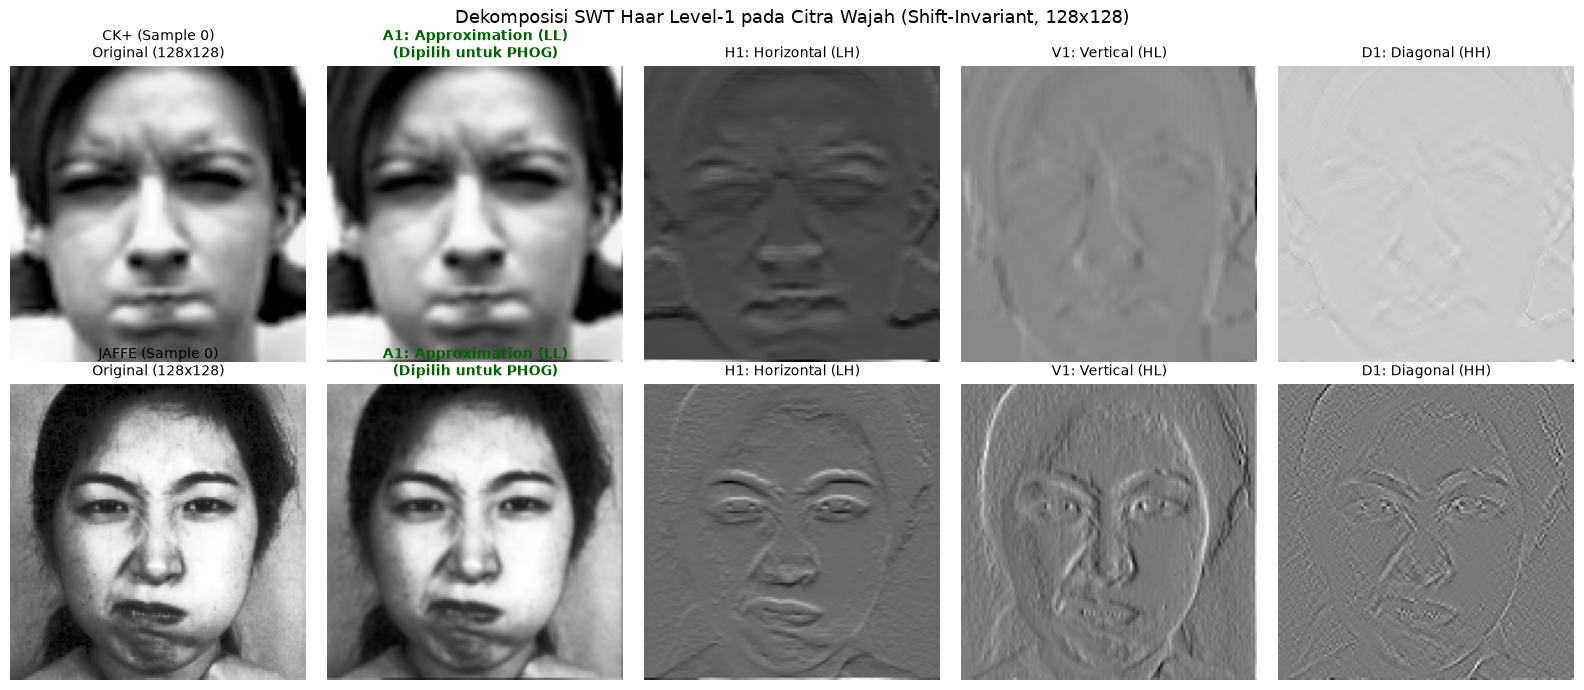

In [4]:
# Visualisasi 4 subband frekuensi untuk sampel citra CK+ dan JAFFE
sample_ck = X_ck[0]
sample_jf = X_jf[0]

sub_ck = swt_haar_level1(sample_ck)
sub_jf = swt_haar_level1(sample_jf)

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
row_data = [
    ("CK+ (Sample 0)", sample_ck, sub_ck),
    ("JAFFE (Sample 0)", sample_jf, sub_jf),
]

for row_idx, (title_prefix, orig_img, sub) in enumerate(row_data):
    axes[row_idx, 0].imshow(orig_img, cmap="gray")
    axes[row_idx, 0].set_title(f"{title_prefix}\nOriginal (128x128)", fontsize=10)
    axes[row_idx, 0].axis("off")

    axes[row_idx, 1].imshow(sub["A1"], cmap="gray")
    axes[row_idx, 1].set_title("A1: Approximation (LL)\n(Dipilih untuk PHOG)", fontsize=10, color="darkgreen", fontweight="bold")
    axes[row_idx, 1].axis("off")

    axes[row_idx, 2].imshow(sub["H1"], cmap="gray")
    axes[row_idx, 2].set_title("H1: Horizontal (LH)", fontsize=10)
    axes[row_idx, 2].axis("off")

    axes[row_idx, 3].imshow(sub["V1"], cmap="gray")
    axes[row_idx, 3].set_title("V1: Vertical (HL)", fontsize=10)
    axes[row_idx, 3].axis("off")

    axes[row_idx, 4].imshow(sub["D1"], cmap="gray")
    axes[row_idx, 4].set_title("D1: Diagonal (HH)", fontsize=10)
    axes[row_idx, 4].axis("off")

plt.suptitle("Dekomposisi SWT Haar Level-1 pada Citra Wajah (Shift-Invariant, 128x128)", fontsize=13, y=0.98)
plt.tight_layout()
plt.show()

## 4. Landasan Teori: PHOG pada Subband A1 (§4.2.2 & §5.1, hal. 1475, 1478)

### Mengapa PHOG Dihitung Hanya pada Subband A1?
Sesuai Jurnal §4.2.3 dan Persamaan (3)–(4):
$$[A_j, D_j] = \text{SWT}(I)$$
$$F_{vec} = \text{PHOG}(A_j)$$
Subband aproksimasi $A_1$ memuat energi frekuensi rendah yang merepresentasikan bentuk anatomis wajah dan deformasi otot ekspresi secara dominan, sekaligus terhindar dari noise acak frekuensi tinggi.

### Parameter Spesifikasi Resmi Jurnal:
1. **Kedalaman Piramida Spasial ($L = 3$):**
   Pada setiap tingkat piramida $l \in \{0, 1, 2, 3\}$, citra dibagi menjadi $2^l \times 2^l$ sel spasial:
   - **Level 0 ($l=0$):** $2^0 \times 2^0 = 1$ sel ($128 \times 128$ px) $\rightarrow 1 \times 8 = 8$ bin (Konteks global wajah penuh).
   - **Level 1 ($l=1$):** $2^1 \times 2^1 = 4$ sel ($64 \times 64$ px) $\rightarrow 4 \times 8 = 32$ bin (Pembagian 4 kuadran wajah).
   - **Level 2 ($l=2$):** $2^2 \times 2^2 = 16$ sel ($32 \times 32$ px) $\rightarrow 16 \times 8 = 128$ bin (Region mata kiri, mata kanan, hidung, mulut).
   - **Level 3 ($l=3$):** $2^3 \times 2^3 = 64$ sel ($16 \times 16$ px) $\rightarrow 64 \times 8 = 512$ bin (Detail kontur lokal tepi bibir, alis, kerutan).
   
   $$\text{Total Sel} = \sum_{l=0}^{3} 4^l = 1 + 4 + 16 + 64 = 85 \text{ sel}$$

2. **Kuantisasi Orientasi Gradien ($K = 8$):**
   Rentang sudut $[0 - 360^\circ)$ dikuantisasi menjadi 8 bin dengan lebar interval $45^\circ$:
   - Bin 0: $[0^\circ, 45^\circ)$
   - Bin 1: $[45^\circ, 90^\circ)$
   - Bin 2: $[90^\circ, 135^\circ)$
   - Bin 3: $[135^\circ, 180^\circ)$
   - Bin 4: $[180^\circ, 225^\circ)$
   - Bin 5: $[225^\circ, 270^\circ)$
   - Bin 6: $[270^\circ, 315^\circ)$
   - Bin 7: $[315^\circ, 360^\circ)$

3. **Pembobotan Gradien:**
   Magnitude gradien dihitung via operator Sobel $3 \times 3$:
   $$dx = \text{Sobel}_x(A_1), \quad dy = \text{Sobel}_y(A_1)$$
   $$\text{magnitude} = \sqrt{dx^2 + dy^2}, \quad \theta = \text{atan2}(dy, dx) \pmod{360^\circ}$$
   Setiap piksel menyumbangkan magnitudo gradiennya ke bin orientasi yang sesuai di dalam selnya.

4. **Skema Normalisasi Piramida Spasial (*Per-Level $L_2$ Normalization*):**
   Jurnal menyatakan: *"further normalised considering all the pyramid levels"*.
   Kita menerapkan normalisasi $L_2$ secara independen pada setiap level $l$:
   $$v_l' = \frac{v_l}{\|v_l\|_2 + \epsilon}$$
   Lalu dikonkatenasi: $F_{vec} = [v_0', v_1', v_2', v_3']$.
   Hal ini menjamin Level 0 (1 sel) memiliki bobot seimbang dengan Level 3 (64 sel), sehingga informasi bentuk global tidak tenggelam oleh jumlah sel lokal.

5. **Panjang Vektor Fitur Final:**
   $$F_{vz} = K \times \sum_{l=0}^{L} 4^l = 8 \times 85 = \mathbf{680} \text{ fitur}$$

In [5]:
def compute_gradients(
    image: np.ndarray,
    ksize: int = 3,
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Menghitung magnitudo dan sudut orientasi gradien citra menggunakan operator Sobel.

    Parameters
    ----------
    image : np.ndarray
        Citra 2D (subband A1).
    ksize : int, default=3
        Ukuran kernel Sobel (3x3).

    Returns
    -------
    magnitude : np.ndarray
        Peta magnitudo gradien sqrt(dx^2 + dy^2), dtype float64.
    angle_deg : np.ndarray
        Peta sudut orientasi dalam derajat rentang [0, 360), dtype float64.
    """
    img_f = np.asarray(image, dtype=np.float64)

    # Operator Sobel horizontal (dx) dan vertikal (dy)
    dx = cv2.Sobel(img_f, cv2.CV_64F, 1, 0, ksize=ksize)
    dy = cv2.Sobel(img_f, cv2.CV_64F, 0, 1, ksize=ksize)

    # Magnitudo gradien
    magnitude = np.hypot(dx, dy)

    # Sudut orientasi [0, 360) derajat
    angle_rad = np.arctan2(dy, dx)
    angle_deg = np.rad2deg(angle_rad)
    angle_deg = (angle_deg + 360.0) % 360.0

    return magnitude, angle_deg


def phog(
    img: np.ndarray,
    L: int = 3,
    K: int = 8,
    angle_range: Tuple[float, float] = (0.0, 360.0),
    norm: str = "per_level",
    eps: float = 1e-7,
) -> np.ndarray:
    """
    Ekstraksi Pyramid of Histograms of Orientation Gradients (PHOG).

    Sesuai Jurnal Kar et al. (2021) Bagian §4.2.2 & §5.1:
    - Subband: A1 (aproksimasi SWT).
    - Piramida spasial: L=3 (85 sel: 1 + 4 + 16 + 64).
    - Bin orientasi: K=8 bin dalam rentang [0, 360°).
    - Vektor akhir: (680,) float32.
    """
    if img.ndim != 2:
        raise ValueError(f"Input PHOG harus berupa citra 2D, didapat shape {img.shape}")

    h, w = img.shape
    magnitude, angle_deg = compute_gradients(img)

    min_ang, max_ang = angle_range
    ang_span = max_ang - min_ang
    bin_width = ang_span / K

    # Tentukan indeks bin orientasi tiap piksel (0 s.d. K-1)
    rel_angle = np.clip(angle_deg - min_ang, 0.0, ang_span - 1e-9)
    bin_idx = np.floor(rel_angle / bin_width).astype(np.int32)
    bin_idx = np.clip(bin_idx, 0, K - 1)

    # Hitung histogram pada grid terdalam level L (2^L x 2^L sel)
    # Untuk L=3 dan citra 128x128: 8x8 sel, tiap sel berukuran 16x16 piksel
    max_cells = 2 ** L
    cell_h = h / max_cells
    cell_w = w / max_cells

    finest_grid = np.zeros((max_cells, max_cells, K), dtype=np.float64)
    for i in range(max_cells):
        r0 = int(round(i * cell_h))
        r1 = int(round((i + 1) * cell_h))
        for j in range(max_cells):
            c0 = int(round(j * cell_w))
            c1 = int(round((j + 1) * cell_w))

            c_bins = bin_idx[r0:r1, c0:c1].ravel()
            c_mags = magnitude[r0:r1, c0:c1].ravel()
            finest_grid[i, j] = np.bincount(c_bins, weights=c_mags, minlength=K)

    # Bangun fitur piramida secara hierarkis dari level 0 s.d. L
    level_features = []
    for l in range(L + 1):
        cells_l = 2 ** l
        step = max_cells // cells_l
        hists_l = []

        for i in range(cells_l):
            for j in range(cells_l):
                block = finest_grid[i * step : (i + 1) * step, j * step : (j + 1) * step]
                cell_hist = block.sum(axis=(0, 1))
                hists_l.append(cell_hist)

        v_l = np.concatenate(hists_l).astype(np.float32)

        if norm == "per_level":
            norm_val = np.linalg.norm(v_l)
            if norm_val > eps:
                v_l = v_l / norm_val

        level_features.append(v_l)

    # Konkatenasi seluruh level piramida (L0 + L1 + L2 + L3)
    phog_vec = np.concatenate(level_features).astype(np.float32)

    if norm == "global":
        norm_val = np.linalg.norm(phog_vec)
        if norm_val > eps:
            phog_vec = phog_vec / norm_val

    return phog_vec

# Verifikasi dimensi dan sifat normalisasi PHOG pada 1 citra
demo_feat = phog(demo_subbands["A1"], L=3, K=8, norm="per_level")
print(f"✓ Output PHOG shape: {demo_feat.shape}, dtype={demo_feat.dtype}")
print(f"  Norma L2 keseluruhan vektor (4 level @ 1.0): {np.linalg.norm(demo_feat):.4f}")
print(f"  Norma L2 Level 0 (8 bin)   : {np.linalg.norm(demo_feat[0:8]):.4f}")
print(f"  Norma L2 Level 1 (32 bin)  : {np.linalg.norm(demo_feat[8:40]):.4f}")
print(f"  Norma L2 Level 2 (128 bin) : {np.linalg.norm(demo_feat[40:168]):.4f}")
print(f"  Norma L2 Level 3 (512 bin) : {np.linalg.norm(demo_feat[168:680]):.4f}")

✓ Output PHOG shape: (680,), dtype=float32
  Norma L2 keseluruhan vektor (4 level @ 1.0): 2.0000
  Norma L2 Level 0 (8 bin)   : 1.0000
  Norma L2 Level 1 (32 bin)  : 1.0000
  Norma L2 Level 2 (128 bin) : 1.0000
  Norma L2 Level 3 (512 bin) : 1.0000


✓ Visualisasi piramida berhasil disimpan ke: C:\Sora Games\personal needs\KULIAH\SEMESTER 5\PCVK\2nd try\TA-PCVK\reports\figures\phog_levels_visualization.png


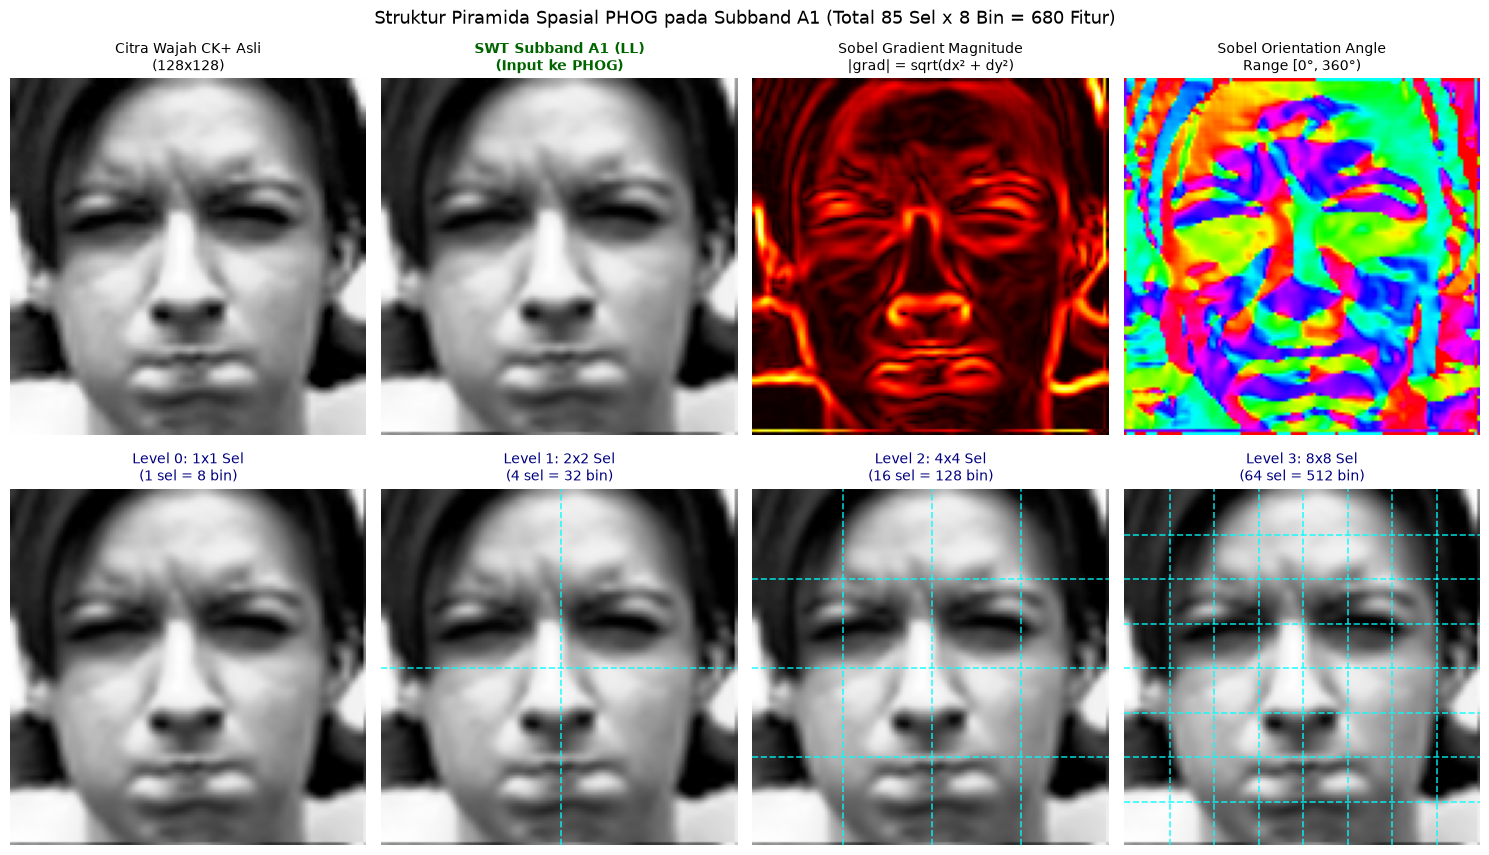

In [6]:
# Visualisasi Grid Piramida Spasial PHOG Level 0, 1, 2, dan 3
a1_demo = sub_ck["A1"]
mag_demo, ang_demo = compute_gradients(a1_demo)

fig = plt.figure(figsize=(15, 9))
gs = fig.add_gridspec(2, 4)

ax_orig = fig.add_subplot(gs[0, 0])
ax_orig.imshow(sample_ck, cmap="gray")
ax_orig.set_title("Citra Wajah CK+ Asli\n(128x128)", fontsize=10)
ax_orig.axis("off")

ax_a1 = fig.add_subplot(gs[0, 1])
ax_a1.imshow(a1_demo, cmap="gray")
ax_a1.set_title("SWT Subband A1 (LL)\n(Input ke PHOG)", fontsize=10, color="darkgreen", fontweight="bold")
ax_a1.axis("off")

ax_mag = fig.add_subplot(gs[0, 2])
ax_mag.imshow(mag_demo, cmap="hot")
ax_mag.set_title("Sobel Gradient Magnitude\n|grad| = sqrt(dx² + dy²)", fontsize=10)
ax_mag.axis("off")

ax_ang = fig.add_subplot(gs[0, 3])
ax_ang.imshow(ang_demo, cmap="hsv", vmin=0, vmax=360)
ax_ang.set_title("Sobel Orientation Angle\nRange [0°, 360°)", fontsize=10)
ax_ang.axis("off")

# Visualisasi grid per level pada baris ke-2
grid_levels = [
    (0, "Level 0: 1x1 Sel\n(1 sel = 8 bin)", 1),
    (1, "Level 1: 2x2 Sel\n(4 sel = 32 bin)", 2),
    (2, "Level 2: 4x4 Sel\n(16 sel = 128 bin)", 4),
    (3, "Level 3: 8x8 Sel\n(64 sel = 512 bin)", 8),
]

for col_idx, (lvl, title, n_cells) in enumerate(grid_levels):
    ax = fig.add_subplot(gs[1, col_idx])
    ax.imshow(a1_demo, cmap="gray")
    step = 128 / n_cells
    for line in range(1, n_cells):
        ax.axhline(line * step, color="cyan", linewidth=1.2, linestyle="--", alpha=0.8)
        ax.axvline(line * step, color="cyan", linewidth=1.2, linestyle="--", alpha=0.8)
    ax.set_title(title, fontsize=10, color="navy")
    ax.axis("off")

plt.suptitle("Struktur Piramida Spasial PHOG pada Subband A1 (Total 85 Sel x 8 Bin = 680 Fitur)", fontsize=13, y=0.98)
plt.tight_layout()

# Simpan figur visualisasi
fig_path = repo_root / "reports" / "figures" / "phog_levels_visualization.png"
fig_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
print(f"✓ Visualisasi piramida berhasil disimpan ke: {fig_path}")
plt.show()

## 5. Implementasi Fungsi Wrapper Ekstraksi Batch: `extract_features`

Fungsi `extract_features(X)` mengintegrasikan seluruh alur:
$$I \xrightarrow{\text{SWT Haar Level-1}} A_1 \xrightarrow{\text{PHOG}(L=3, K=8)} \mathbf{F} \in \mathbb{R}^{680}$$

Mendukung input citra tunggal $(128, 128) \rightarrow (680,)$ maupun batch matriks $(N, 128, 128) \rightarrow (N, 680)$ bertipe `float32`.

In [7]:
def extract_features(
    X: np.ndarray,
    L: int = 3,
    K: int = 8,
    norm: str = "per_level",
) -> np.ndarray:
    """
    Mengekstraksi fitur hybrid menyeluruh (SWT Haar Level-1 -> Subband A1 -> PHOG).

    Sesuai Jurnal Kar et al. (2021) Persamaan (3)–(4):
        [Aj, Dj] = SWT(I)
        Fvec     = PHOG(Aj)

    Parameters
    ----------
    X : np.ndarray
        Array citra wajah 2D (128, 128) atau batch citra 3D (N, 128, 128).
    L : int, default=3
        Level piramida PHOG (85 sel).
    K : int, default=8
        Jumlah bin orientasi PHOG.
    norm : str, default='per_level'
        Skema normalisasi PHOG.

    Returns
    -------
    np.ndarray
        Array 1D (680,) untuk citra tunggal atau matriks 2D (N, 680) untuk batch.
        Tipe data float32, tanpa NaN dan Inf.
    """
    if X.ndim == 2:
        subbands = swt_haar_level1(X)
        a1 = subbands["A1"]
        return phog(a1, L=L, K=K, norm=norm)

    elif X.ndim == 3:
        n_samples = X.shape[0]
        expected_dim = K * sum(4 ** l for l in range(L + 1))  # 680
        features = np.empty((n_samples, expected_dim), dtype=np.float32)

        for i in range(n_samples):
            subbands = swt_haar_level1(X[i])
            a1 = subbands["A1"]
            features[i] = phog(a1, L=L, K=K, norm=norm)

        return features

    else:
        raise ValueError(
            f"Input X harus berdimensi 2 (H, W) atau 3 (N, H, W), diterima bentuk {X.shape} (ndim={X.ndim})."
        )

# Uji ekstraksi pada batch kecil (2 sampel)
batch_test = extract_features(X_ck[:2])
print(f"✓ Ekstraksi batch test berhasil: shape={batch_test.shape}, dtype={batch_test.dtype}")

✓ Ekstraksi batch test berhasil: shape=(2, 680), dtype=float32


## 6. Ekstraksi Fitur Seluruh Dataset (CK+ & JAFFE)

Mengekstrak seluruh 981 citra CK+ dan 213 citra JAFFE. Kita juga mencatat waktu eksekusi untuk menganalisis performa efisiensi komputasi.

In [8]:
print(f"Memulai ekstraksi fitur seluruh sampel CK+ ({len(X_ck)} citra)...")
t0_ck = time.perf_counter()
F_ck = extract_features(X_ck, L=3, K=8, norm="per_level")
t1_ck = time.perf_counter()
waktu_ck = t1_ck - t0_ck
fps_ck = len(X_ck) / waktu_ck

print(f"✓ Ekstraksi CK+ selesai dalam {waktu_ck:.2f} detik ({fps_ck:.1f} citra/detik).")
print(f"  Shape F_ck: {F_ck.shape}, dtype: {F_ck.dtype}")

print()
print(f"Memulai ekstraksi fitur seluruh sampel JAFFE ({len(X_jf)} citra)...")
t0_jf = time.perf_counter()
F_jaffe = extract_features(X_jf, L=3, K=8, norm="per_level")
t1_jf = time.perf_counter()
waktu_jf = t1_jf - t0_jf
fps_jf = len(X_jf) / waktu_jf

print(f"✓ Ekstraksi JAFFE selesai dalam {waktu_jf:.2f} detik ({fps_jf:.1f} citra/detik).")
print(f"  Shape F_jaffe: {F_jaffe.shape}, dtype: {F_jaffe.dtype}")

Memulai ekstraksi fitur seluruh sampel CK+ (981 citra)...


✓ Ekstraksi CK+ selesai dalam 3.12 detik (314.1 citra/detik).
  Shape F_ck: (981, 680), dtype: float32

Memulai ekstraksi fitur seluruh sampel JAFFE (213 citra)...


✓ Ekstraksi JAFFE selesai dalam 0.64 detik (332.4 citra/detik).
  Shape F_jaffe: (213, 680), dtype: float32


## 7. Verifikasi Wajib (Sel Assert)

Sesuai spesifikasi penugasan A2, kode wajib memenuhi pengujian assert berikut:
```python
assert F_ck.shape    == (981, 680)
assert F_jaffe.shape == (213, 680)
assert np.isfinite(F_ck).all() and np.isfinite(F_jaffe).all()
```

In [9]:
# --- SEL VERIFIKASI WAJIB PENUGASAN A2 ---
assert F_ck.shape == (981, 680), f"Bentuk CK+ salah: {F_ck.shape}"
assert F_jaffe.shape == (213, 680), f"Bentuk JAFFE salah: {F_jaffe.shape}"
assert np.isfinite(F_ck).all(), "Terdapat nilai NaN atau Inf pada fitur CK+!"
assert np.isfinite(F_jaffe).all(), "Terdapat nilai NaN atau Inf pada fitur JAFFE!"

print("=" * 65)
print("✓ VERIFIKASI WAJIB LOLOS 100%!")
print(f"  - Matriks Fitur CK+   : {F_ck.shape} float32 (semua elemen berhingga)")
print(f"  - Matriks Fitur JAFFE : {F_jaffe.shape} float32 (semua elemen berhingga)")
print("=" * 65)

✓ VERIFIKASI WAJIB LOLOS 100%!
  - Matriks Fitur CK+   : (981, 680) float32 (semua elemen berhingga)
  - Matriks Fitur JAFFE : (213, 680) float32 (semua elemen berhingga)


## 8. Analisis Statistik Karakteristik Fitur

Menganalisis statistik fitur gabungan:
- **Sparsity:** Persentase elemen nol dalam vektor fitur.
- **Rentang Nilai:** Nilai minimum, maksimum, rata-rata, dan standar deviasi.
- **Visualisasi Profil Fitur:** Perbandingan profil 680 fitur antar kelas ekspresi berbeda.

--- Statistik Fitur ---
CK+   -> Rerata: 0.04181, Std: 0.06430, Min: 0.00000, Max: 0.52685
         Sparsity (elemen nol): 5.64%
JAFFE -> Rerata: 0.04313, Std: 0.06342, Min: 0.00000, Max: 0.52792
         Sparsity (elemen nol): 1.22%


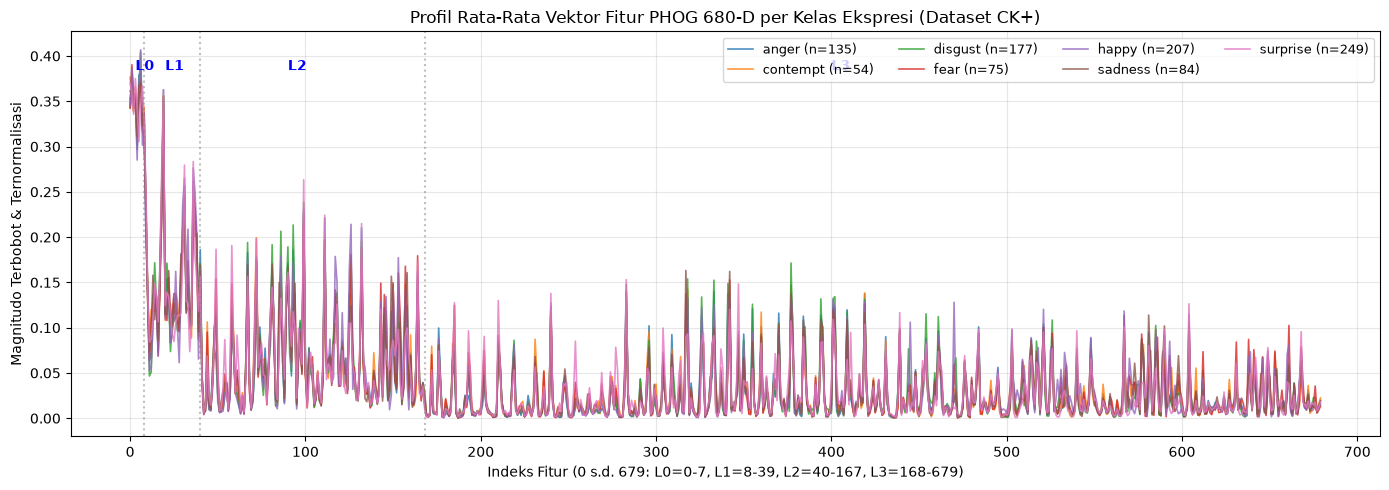

In [10]:
# 1. Analisis Sparsity (Persentase elemen bernilai nol)
zero_ck = np.mean(F_ck == 0.0) * 100.0
zero_jf = np.mean(F_jaffe == 0.0) * 100.0

print("--- Statistik Fitur ---")
print(f"CK+   -> Rerata: {F_ck.mean():.5f}, Std: {F_ck.std():.5f}, Min: {F_ck.min():.5f}, Max: {F_ck.max():.5f}")
print(f"         Sparsity (elemen nol): {zero_ck:.2f}%")
print(f"JAFFE -> Rerata: {F_jaffe.mean():.5f}, Std: {F_jaffe.std():.5f}, Min: {F_jaffe.min():.5f}, Max: {F_jaffe.max():.5f}")
print(f"         Sparsity (elemen nol): {zero_jf:.2f}%")

# 2. Visualisasi Rata-rata Profil Fitur 680-D untuk Tiap Kelas Emosi CK+
fig, ax = plt.subplots(figsize=(14, 5))
for cls_idx, cls_name in enumerate(classes_ck):
    mask = (y_ck == cls_idx)
    if mask.sum() > 0:
        mean_profile = F_ck[mask].mean(axis=0)
        ax.plot(mean_profile, label=f"{cls_name} (n={mask.sum()})", alpha=0.8, linewidth=1.2)

ax.set_title("Profil Rata-Rata Vektor Fitur PHOG 680-D per Kelas Ekspresi (Dataset CK+)", fontsize=12)
ax.set_xlabel("Indeks Fitur (0 s.d. 679: L0=0-7, L1=8-39, L2=40-167, L3=168-679)", fontsize=10)
ax.set_ylabel("Magnitudo Terbobot & Ternormalisasi", fontsize=10)
ax.axvline(8, color="gray", linestyle=":", alpha=0.5)
ax.axvline(40, color="gray", linestyle=":", alpha=0.5)
ax.axvline(168, color="gray", linestyle=":", alpha=0.5)
ax.text(3, ax.get_ylim()[1]*0.9, "L0", color="blue", fontweight="bold")
ax.text(20, ax.get_ylim()[1]*0.9, "L1", color="blue", fontweight="bold")
ax.text(90, ax.get_ylim()[1]*0.9, "L2", color="blue", fontweight="bold")
ax.text(400, ax.get_ylim()[1]*0.9, "L3", color="blue", fontweight="bold")
ax.legend(loc="upper right", ncol=4, fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Menyimpan Artefak Fitur untuk Anggota 3 (A3)

Menyimpan matriks fitur hasil ekstraksi ke direktori `data/`:
- `data/ck_features.npz`
- `data/jaffe_features.npz`

Setiap file `.npz` berisi:
- `F`: Matriks fitur $(N, 680)$ bertipe `float32`.
- `y`: Array label emosi $(N,)$ bertipe `int8`.
- `subjects`: Array identitas subjek $(N,)$.
- `class_names`: Daftar nama kelas emosi.

In [11]:
out_ck_path = repo_root / "data" / "ck_features.npz"
out_jf_path = repo_root / "data" / "jaffe_features.npz"

np.savez_compressed(
    out_ck_path,
    F=F_ck,
    y=y_ck,
    subjects=subjects_ck,
    class_names=np.array(classes_ck),
)
print(f"✓ Berhasil menyimpan artefak CK+ ke: {out_ck_path}")
print(f"  Ukuran file: {out_ck_path.stat().st_size / (1024 * 1024):.2f} MB")

np.savez_compressed(
    out_jf_path,
    F=F_jaffe,
    y=y_jf,
    subjects=subjects_jf,
    class_names=np.array(classes_jf),
)
print(f"✓ Berhasil menyimpan artefak JAFFE ke: {out_jf_path}")
print(f"  Ukuran file: {out_jf_path.stat().st_size / (1024 * 1024):.2f} MB")

✓ Berhasil menyimpan artefak CK+ ke: C:\Sora Games\personal needs\KULIAH\SEMESTER 5\PCVK\2nd try\TA-PCVK\data\ck_features.npz
  Ukuran file: 2.26 MB
✓ Berhasil menyimpan artefak JAFFE ke: C:\Sora Games\personal needs\KULIAH\SEMESTER 5\PCVK\2nd try\TA-PCVK\data\jaffe_features.npz
  Ukuran file: 0.51 MB


## 10. Verifikasi Ulang Pembacaan Artefak Output

Memastikan file `.npz` yang disimpan di disk dapat dimuat kembali dengan sempurna tanpa korupsi data:

In [12]:
test_ck = np.load(out_ck_path)
test_jf = np.load(out_jf_path)

assert test_ck["F"].shape == (981, 680)
assert test_jf["F"].shape == (213, 680)
assert test_ck["F"].dtype == np.float32
assert test_jf["F"].dtype == np.float32
assert len(test_ck["y"]) == 981
assert len(test_jf["y"]) == 213
assert (test_ck["class_names"] == np.array(classes_ck)).all()
assert (test_jf["class_names"] == np.array(classes_jf)).all()

print("✓ Validasi pembacaan artefak disk sukses!")
print(f"  CK+ keys   : {list(test_ck.keys())}")
print(f"  JAFFE keys : {list(test_jf.keys())}")

✓ Validasi pembacaan artefak disk sukses!
  CK+ keys   : ['F', 'y', 'subjects', 'class_names']
  JAFFE keys : ['F', 'y', 'subjects', 'class_names']


## 11. Ekspor Modul Modular `feature-engineering/features.py`

Untuk memfasilitasi kebutuhan Anggota 3 (pelatihan model), Anggota 4 (web inference), dan unit test runner (`pytest`), kita menyinkronkan fungsi modular langsung ke file `feature-engineering/features.py`.

In [13]:
features_py_content = """\"\"\"
Modul Ekstraksi Fitur Hybrid: SWT Haar Level-1 + PHOG.

Replikasi Jurnal:
Kar, N.B., Nayak, D.R., Babu, K.S., & Zhang, Y.-D. (2021).
"A hybrid feature descriptor with Jaya optimised least squares SVM for
facial expression recognition", IET Image Processing, 15(7), 1471–1483.
DOI: 10.1049/ipr2.12118

Modul ini menyediakan:
1. swt_haar_level1(img) -> Dekomposisi SWT Haar level-1 (A1, H1, V1, D1)
2. phog(img, L=3, K=8)  -> PHOG 680-D pada subband aproksimasi A1
3. extract_features(X)  -> Ekstraksi fitur citra tunggal atau batch (N, 680)
\"\"\"

from typing import Dict, Optional, Tuple, Union
import cv2
import numpy as np
import pywt


def swt_haar_level1(img: np.ndarray) -> Dict[str, np.ndarray]:
    \"\"\"
    Dekomposisi Stationary Wavelet Transform (SWT) level-1 dengan wavelet Haar.
    Menghasilkan 4 subband 128x128 piksel: A1 (LL), H1 (LH), V1 (HL), D1 (HH).
    \"\"\"
    if not isinstance(img, np.ndarray):
        img = np.asarray(img)

    if img.ndim != 2:
        raise ValueError(
            f"Citra harus berupa array 2D (grayscale), tetapi diterima array berdimensi {img.shape} (ndim={img.ndim})."
        )

    img_float = img.astype(np.float64) if img.dtype != np.float64 else img

    h, w = img_float.shape
    if h % 2 != 0 or w % 2 != 0:
        raise ValueError(f"Dimensi citra ({h}, {w}) harus genap untuk SWT level-1.")

    coeffs = pywt.swt2(img_float, wavelet="haar", level=1, trim_approx=True)
    cA = coeffs[0]
    cH, cV, cD = coeffs[1]

    return {
        "A1": cA,
        "H1": cH,
        "V1": cV,
        "D1": cD,
    }


def compute_gradients(
    image: np.ndarray,
    ksize: int = 3,
) -> Tuple[np.ndarray, np.ndarray]:
    \"\"\"Menghitung magnitudo dan orientasi sudut [0, 360) via Sobel.\"\"\"
    img_f = np.asarray(image, dtype=np.float64)
    dx = cv2.Sobel(img_f, cv2.CV_64F, 1, 0, ksize=ksize)
    dy = cv2.Sobel(img_f, cv2.CV_64F, 0, 1, ksize=ksize)
    magnitude = np.hypot(dx, dy)
    angle_rad = np.arctan2(dy, dx)
    angle_deg = (np.rad2deg(angle_rad) + 360.0) % 360.0
    return magnitude, angle_deg


def phog(
    img: np.ndarray,
    L: int = 3,
    K: int = 8,
    angle_range: Tuple[float, float] = (0.0, 360.0),
    norm: str = "per_level",
    eps: float = 1e-7,
) -> np.ndarray:
    \"\"\"Ekstraksi PHOG dari subband A1 (85 sel x 8 bin = 680-D float32).\"\"\"
    if img.ndim != 2:
        raise ValueError(f"Input PHOG harus berupa citra 2D, didapat shape {img.shape}")

    h, w = img.shape
    magnitude, angle_deg = compute_gradients(img)

    min_ang, max_ang = angle_range
    ang_span = max_ang - min_ang
    bin_width = ang_span / K

    rel_angle = np.clip(angle_deg - min_ang, 0.0, ang_span - 1e-9)
    bin_idx = np.floor(rel_angle / bin_width).astype(np.int32)
    bin_idx = np.clip(bin_idx, 0, K - 1)

    max_cells = 2 ** L
    cell_h = h / max_cells
    cell_w = w / max_cells

    finest_grid = np.zeros((max_cells, max_cells, K), dtype=np.float64)
    for i in range(max_cells):
        r0 = int(round(i * cell_h))
        r1 = int(round((i + 1) * cell_h))
        for j in range(max_cells):
            c0 = int(round(j * cell_w))
            c1 = int(round((j + 1) * cell_w))
            c_bins = bin_idx[r0:r1, c0:c1].ravel()
            c_mags = magnitude[r0:r1, c0:c1].ravel()
            finest_grid[i, j] = np.bincount(c_bins, weights=c_mags, minlength=K)

    level_features = []
    for l in range(L + 1):
        cells_l = 2 ** l
        step = max_cells // cells_l
        hists_l = []

        for i in range(cells_l):
            for j in range(cells_l):
                block = finest_grid[i * step : (i + 1) * step, j * step : (j + 1) * step]
                cell_hist = block.sum(axis=(0, 1))
                hists_l.append(cell_hist)

        v_l = np.concatenate(hists_l).astype(np.float32)

        if norm == "per_level":
            norm_val = np.linalg.norm(v_l)
            if norm_val > eps:
                v_l = v_l / norm_val

        level_features.append(v_l)

    phog_vec = np.concatenate(level_features).astype(np.float32)

    if norm == "global":
        norm_val = np.linalg.norm(phog_vec)
        if norm_val > eps:
            phog_vec = phog_vec / norm_val

    return phog_vec


def extract_features(
    X: np.ndarray,
    L: int = 3,
    K: int = 8,
    norm: str = "per_level",
) -> np.ndarray:
    \"\"\"Ekstraksi fitur hybrid untuk citra tunggal (680,) atau batch (N, 680).\"\"\"
    if X.ndim == 2:
        subbands = swt_haar_level1(X)
        a1 = subbands["A1"]
        return phog(a1, L=L, K=K, norm=norm)

    elif X.ndim == 3:
        n_samples = X.shape[0]
        expected_dim = K * sum(4 ** l for l in range(L + 1))
        features = np.empty((n_samples, expected_dim), dtype=np.float32)

        for i in range(n_samples):
            subbands = swt_haar_level1(X[i])
            a1 = subbands["A1"]
            features[i] = phog(a1, L=L, K=K, norm=norm)

        return features

    else:
        raise ValueError(
            f"Input X harus berdimensi 2 (H, W) atau 3 (N, H, W), diterima bentuk {X.shape} (ndim={X.ndim})."
        )
"""

features_py_path = repo_root / "feature-engineering" / "features.py"
with open(features_py_path, "w", encoding="utf-8") as f:
    f.write(features_py_content.strip() + "\n")

print(f"✓ File modular {features_py_path} berhasil disinkronkan dari kode notebook!")

✓ File modular C:\Sora Games\personal needs\KULIAH\SEMESTER 5\PCVK\2nd try\TA-PCVK\feature-engineering\features.py berhasil disinkronkan dari kode notebook!


## 12. Ringkasan & Panduan Handoff ke A3 (Model & Optimasi)

Tahap **Feature Engineering (A2)** telah selesai 100% sesuai metodologi Kar et al. (2021):

| Komponen | Spesifikasi Resmi Jurnal | Implementasi A2 |
|---|---|---|
| **Transformasi Frekuensi** | SWT Haar Level-1 (undecimated) | `swt_haar_level1()` $\rightarrow$ 4 subband $128 \times 128$ |
| **Subband Pilihan** | $A_1$ (Aproksimasi frekuensi rendah) | Diekstrak eksklusif dari $A_1$ (LL) |
| **Tingkat Piramida ($L$)** | $L = 3$ ($1 + 4 + 16 + 64 = 85$ sel) | 85 sel spasial multiresolusi |
| **Bin Orientasi ($K$)** | $K = 8$ bin, $[0^\circ - 360^\circ)$ | 8 bin terbobot Sobel magnitude |
| **Normalisasi PHOG** | Normalisasi seluruh level | *Per-level $L_2$ normalization* |
| **Dimensi Fitur Final** | **680 dimensi** per citra wajah | $(981, 680)$ & $(213, 680)$ `float32` |

### Catatan Penting untuk Anggota 3 (A3):
1. **Pemuatan Fitur:** A3 cukup memuat `data/ck_features.npz` dan `data/jaffe_features.npz` menggunakan `np.load()`.
2. **Reduksi Dimensi LDA:**
   - Jurnal §4.3 & §5.1 (hal. 1476, 1478): Matriks 680 fitur direduksi menggunakan **Linear Discriminant Analysis (LDA)** menjadi maksimal $C - 1$ komponen:
     - **CK+ (7 kelas):** Reduksi menjadi 6 komponen fitur diskriminatif utama.
     - **JAFFE (7 kelas):** Reduksi menjadi 6 komponen fitur diskriminatif utama.
3. **Klasifikasi:** Fitur hasil LDA kemudian diklasifikasikan menggunakan algoritma **Jaya-LSSVM** dengan skema 5-fold stratified cross-validation.